# KNN Regression – Concrete Compressive Strength Prediction

## Introduction

The objective of this project is to implement the K-Nearest Neighbors (KNN) Regression algorithm to predict the compressive strength of concrete based on its ingredients and age.

The dataset contains numerical information about cement, water, aggregates, and other concrete components. Using these input features, the model learns patterns and predicts the continuous numerical value of concrete compressive strength in MPa.

This project covers data loading, data exploration, preprocessing, feature scaling, model training, prediction, evaluation, distance metric comparison, and prediction on unseen data.

In [5]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# KNN Regression
from sklearn.neighbors import KNeighborsRegressor

# Evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


## Load the Dataset

In [6]:
df = pd.read_excel("Concrete_Data.xls")

print("Dataset loaded successfully!")

display(df.head())

Dataset loaded successfully!


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


## Understand the Dataset

Display the number of rows and columns, column names, and basic information about the dataset.

In [7]:
print("Dataset Shape:", df.shape)

Dataset Shape: (1030, 9)


In [8]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['Cement (component 1)(kg in a m^3 mixture)', 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)', 'Fly Ash (component 3)(kg in a m^3 mixture)', 'Water  (component 4)(kg in a m^3 mixture)', 'Superplasticizer (component 5)(kg in a m^3 mixture)', 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)', 'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)', 'Concrete compressive strength(MPa, megapascals) ']


In [9]:
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Concrete compressive streng

## Display Statistical Summary

Use the describe() function to understand the statistical properties of numerical columns, including mean, standard deviation, minimum, maximum, and quartiles.

In [10]:
display(df.describe())

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


## Check Missing Values

Check whether the dataset contains missing values in any column.

In [11]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Cement (component 1)(kg in a m^3 mixture)                0
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0
Fly Ash (component 3)(kg in a m^3 mixture)               0
Water  (component 4)(kg in a m^3 mixture)                0
Superplasticizer (component 5)(kg in a m^3 mixture)      0
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     0
Fine Aggregate (component 7)(kg in a m^3 mixture)        0
Age (day)                                                0
Concrete compressive strength(MPa, megapascals)          0
dtype: int64


## Check Duplicate Records

Identify duplicate records in the dataset.

In [12]:
print("Total Duplicate Records:", df.duplicated().sum())

Total Duplicate Records: 25


## Handle Missing Values and Duplicates

Handle missing values using the median of each numerical column. Remove exact duplicate records to avoid repeated observations.

In [15]:
# Fill missing numerical values with column median
df = df.fillna(df.median(numeric_only=True))

# Remove duplicate records
df = df.drop_duplicates()

print("Missing values handled.")
print("Duplicate records removed.")

Missing values handled.
Duplicate records removed.


In [16]:
print("\nRemaining Missing Values:")
print(df.isnull().sum())


Remaining Missing Values:
Cement (component 1)(kg in a m^3 mixture)                0
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0
Fly Ash (component 3)(kg in a m^3 mixture)               0
Water  (component 4)(kg in a m^3 mixture)                0
Superplasticizer (component 5)(kg in a m^3 mixture)      0
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     0
Fine Aggregate (component 7)(kg in a m^3 mixture)        0
Age (day)                                                0
Concrete compressive strength(MPa, megapascals)          0
dtype: int64


In [17]:
print("\nUpdated Dataset Shape:", df.shape)


Updated Dataset Shape: (1005, 9)


## Visualize the Target Variable

Visualize the distribution of concrete compressive strength to understand how the target values are distributed.

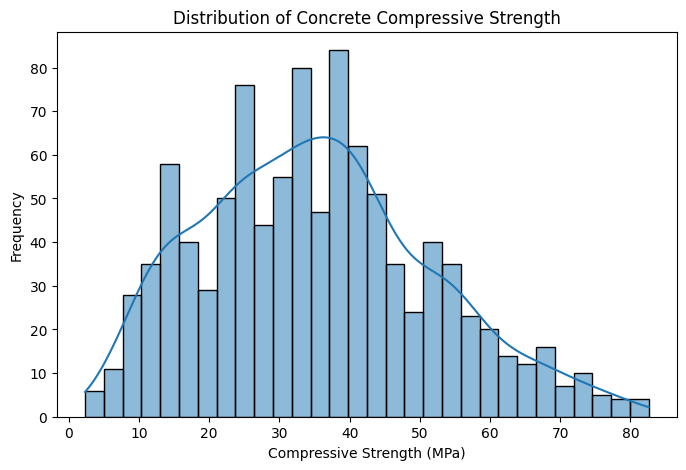

In [18]:
target_column = 'Concrete compressive strength(MPa, megapascals) '

plt.figure(figsize=(8, 5))

sns.histplot(
    df[target_column],
    bins=30,
    kde=True
)

plt.title("Distribution of Concrete Compressive Strength")
plt.xlabel("Compressive Strength (MPa)")
plt.ylabel("Frequency")
plt.show()

## Correlation Heatmap

Use a correlation heatmap to understand the relationship between the numerical features and the target variable.

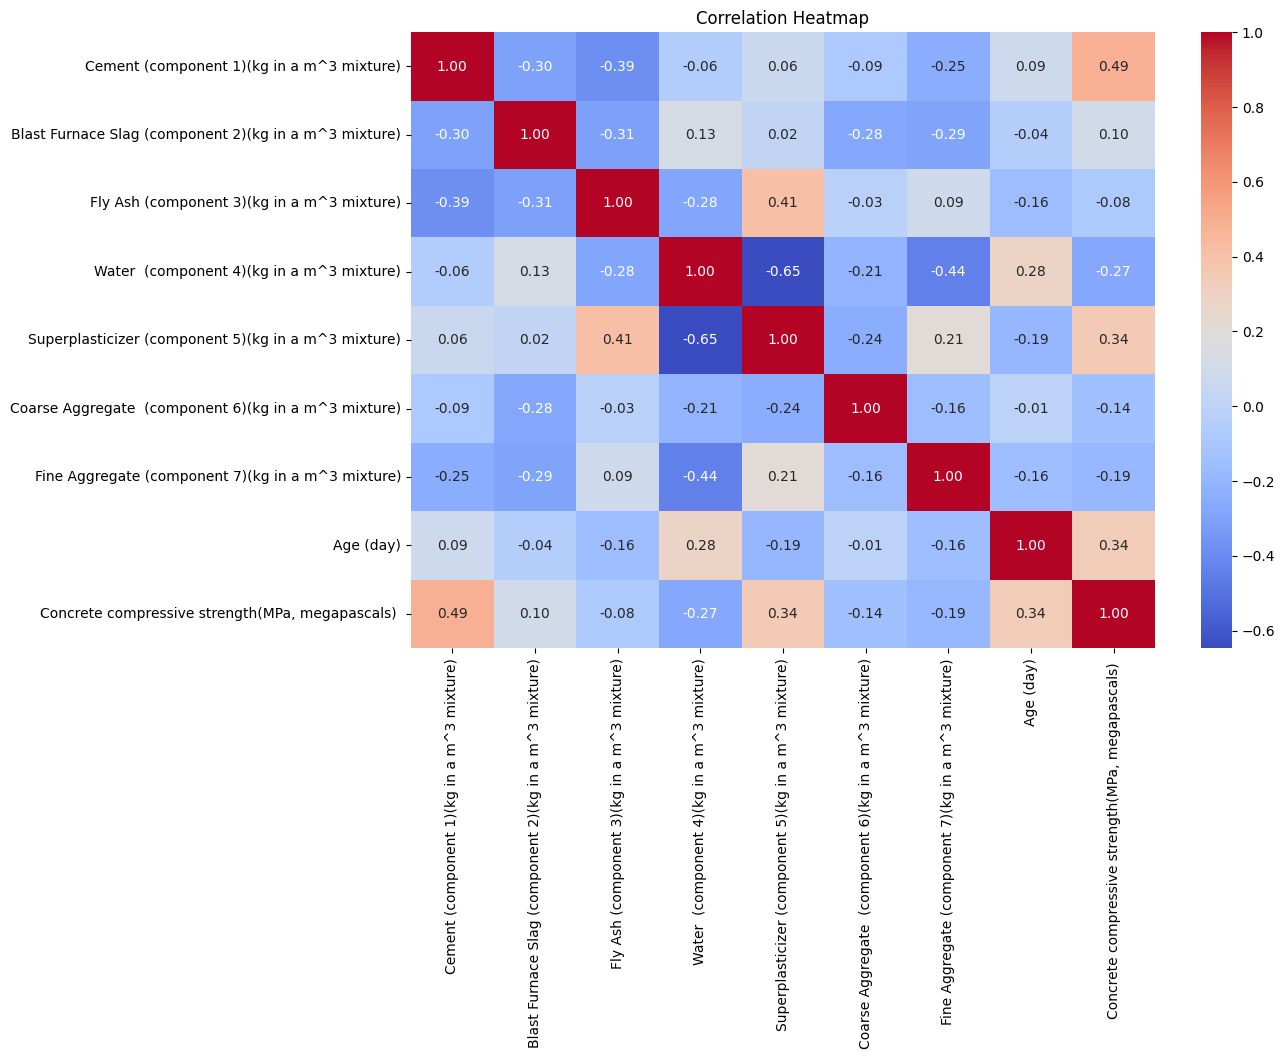

In [19]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

## Separate Input Features (X) and Target Variable (y)

Separate the independent variables (X) and dependent variable (y).

The eight input features describe the concrete composition and age. The target variable represents the concrete compressive strength in MPa.

In [21]:
X = df.drop(columns=[target_column])

y = df[target_column]

print("Input Features (X):")
display(X.head())

Input Features (X):


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day)
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360


In [22]:
print("\nTarget Variable (y):")
display(y.head())


Target Variable (y):


0    79.986111
1    61.887366
2    40.269535
3    41.052780
4    44.296075
Name: Concrete compressive strength(MPa, megapascals) , dtype: float64

In [23]:
print("\nNumber of Input Features:", X.shape[1])
print("Number of Target Values:", y.shape[0])


Number of Input Features: 8
Number of Target Values: 1005


## Split the Dataset into Training and Testing Sets

Split the dataset into 80% training data and 20% testing data.

The training dataset is used to train the model, while the testing dataset is used to evaluate its performance on unseen records.

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (804, 8)
Testing Data: (201, 8)
Training Target: (804,)
Testing Target: (201,)


## Feature Scaling Using StandardScaler

KNN uses distances to identify neighboring observations. Since the input features have different numerical ranges, apply StandardScaler to standardize the features.

Fit the scaler only on the training data and use the same scaler to transform the testing data.

In [25]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

print("\nScaled Training Data:")
display(pd.DataFrame(
    X_train_scaled,
    columns=X.columns
).head())

Feature scaling completed!

Scaled Training Data:


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day)
0,2.436731,-0.837655,-0.875854,-1.872676,3.720458,-1.560057,1.487332,-0.679041
1,1.894738,-0.837655,-0.875854,2.132128,-1.022872,-0.525669,-2.218561,-0.614850
2,-0.010901,-0.837655,0.638578,-0.999239,0.966972,0.016770,1.263643,-0.679041
3,1.519290,-0.837655,-0.875854,1.667534,-1.022872,-1.737417,-0.664237,-0.277844
4,-1.072264,2.070428,-0.875854,0.993872,-1.022872,0.038779,-0.999338,-0.614850


## Implement KNN Regression Model

Create a KNN Regression model using KNeighborsRegressor.

The parameter n_neighbors=5 means the model uses the five nearest training observations to predict the target value.

In [29]:
knn_model = KNeighborsRegressor(
    n_neighbors=5,
    metric='minkowski',
    p=2
)

print("KNN Regression Model Created!")

KNN Regression Model Created!


## Train the KNN Regression Model

Train the model using the scaled training features and their corresponding target values.

In [30]:
knn_model.fit(X_train_scaled, y_train)

print("KNN Regression Model Training Completed!")

KNN Regression Model Training Completed!


## Perform Predictions

Use the trained model to predict concrete compressive strength for the testing dataset.

In [31]:
y_pred = knn_model.predict(X_test_scaled)

print("Predictions Completed!")

Predictions Completed!


## Compare Actual and Predicted Values

Create a DataFrame to compare the actual compressive strength values with the predicted values.

In [32]:
comparison = pd.DataFrame({
    'Actual Strength': y_test.values,
    'Predicted Strength': y_pred
})

display(comparison.head(20))

,Actual Strength,Predicted Strength
0,19.009543,26.404724
1,24.290929,18.093505
2,26.322815,22.985199
3,34.569637,28.344772
4,44.133359,30.587913
5,33.003837,19.544162
6,17.275511,12.871690
7,25.422359,32.137028
8,33.729166,24.880431
9,34.397958,34.658580


## Evaluate the Model Performance

Evaluate the model using four regression metrics:
- MAE: Average absolute prediction error.
- MSE: Average squared prediction error.
- RMSE: Square root of MSE, expressed in the target's original unit.
- R² Score: Measures how well the model explains the variation in the target.

In [33]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("KNN Regression Model Evaluation")
print("--------------------------------")
print("Mean Absolute Error (MAE):", round(mae, 4))
print("Mean Squared Error (MSE):", round(mse, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))
print("R2 Score:", round(r2, 4))

KNN Regression Model Evaluation
--------------------------------
Mean Absolute Error (MAE): 7.1005
Mean Squared Error (MSE): 83.9194
Root Mean Squared Error (RMSE): 9.1608
R2 Score: 0.7187


## Visualize Actual vs Predicted Values

Visualize the actual and predicted concrete compressive strength values. Points closer to the diagonal line indicate better predictions.

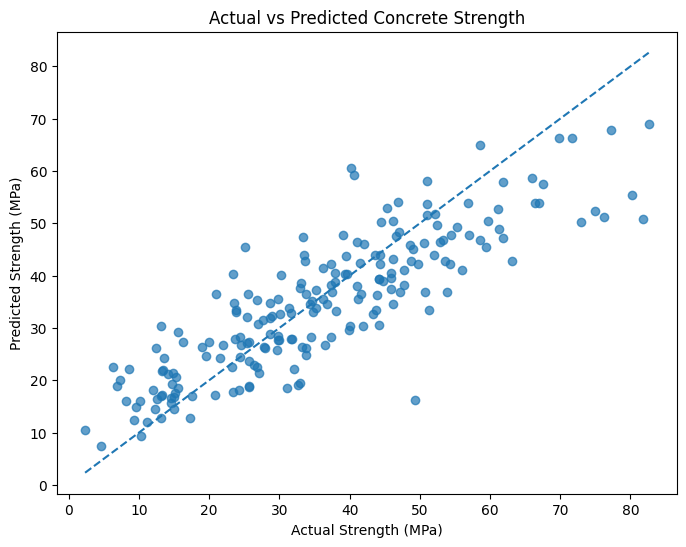

In [34]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.xlabel("Actual Strength (MPa)")
plt.ylabel("Predicted Strength (MPa)")
plt.title("Actual vs Predicted Concrete Strength")
plt.show()

## Compare Different Distance Metrics

Experiment with three distance metrics used in KNN Regression:
1. Minkowski
2. Manhattan
3. Chebyshev

Train separate KNN regression models using each distance metric and compare their performance using MAE, MSE, RMSE, and R² Score.

In [35]:
metrics = ['minkowski', 'manhattan', 'chebyshev']

results = []

for metric in metrics:

    model = KNeighborsRegressor(
        n_neighbors=5,
        metric=metric
    )

    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_test_scaled)

    mae = mean_absolute_error(y_test, predictions)

    mse = mean_squared_error(y_test, predictions)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, predictions)

    results.append({
        'Distance Metric': metric,
        'MAE': mae,
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

print("Distance Metric Comparison:")
display(results_df.round(4))

Distance Metric Comparison:


,Distance Metric,MAE,MSE,RMSE,R2 Score
0,minkowski,7.1005,83.9194,9.1608,0.7187
1,manhattan,7.2894,89.7965,9.4761,0.6990
2,chebyshev,7.6627,98.0304,9.9010,0.6714


## Visualize Distance Metric Comparison

Compare the MAE, RMSE, and R² scores obtained using different distance metrics.

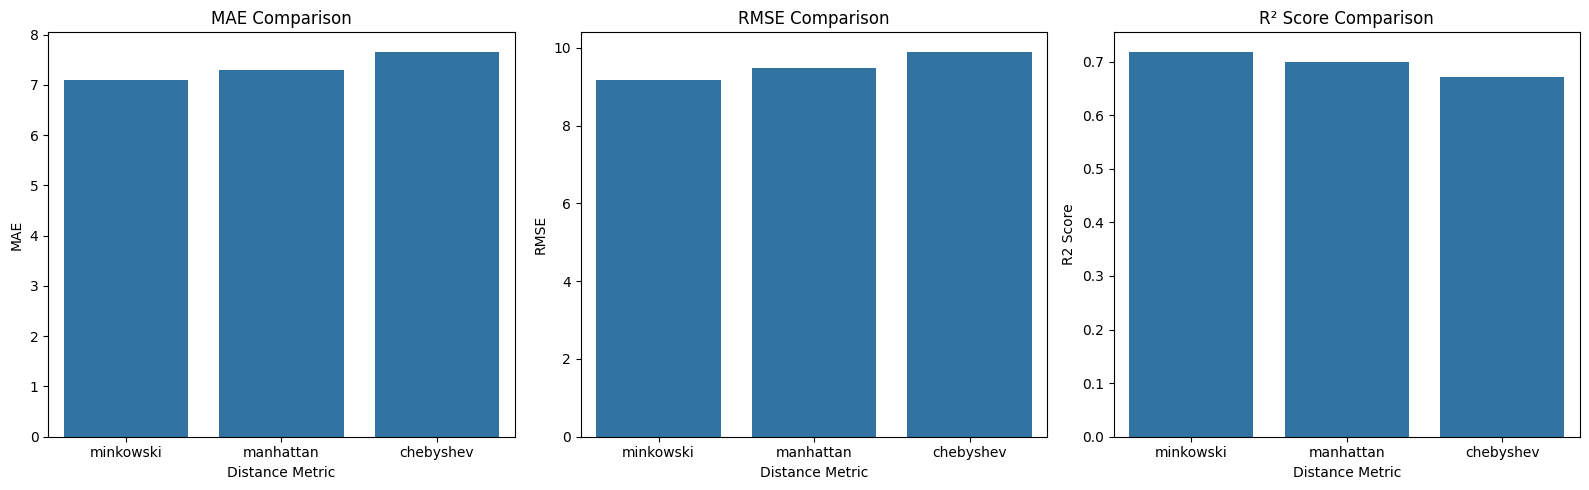

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.barplot(
    data=results_df,
    x='Distance Metric',
    y='MAE',
    ax=axes[0]
)
axes[0].set_title("MAE Comparison")

sns.barplot(
    data=results_df,
    x='Distance Metric',
    y='RMSE',
    ax=axes[1]
)
axes[1].set_title("RMSE Comparison")

sns.barplot(
    data=results_df,
    x='Distance Metric',
    y='R2 Score',
    ax=axes[2]
)
axes[2].set_title("R² Score Comparison")

plt.tight_layout()
plt.show()

## Identify the Best Distance Metric

Identify the best-performing distance metric based on the lowest MAE.

In [37]:
best_result = results_df.loc[results_df['MAE'].idxmin()]

print("Best Distance Metric:", best_result['Distance Metric'])
print("MAE:", round(best_result['MAE'], 4))
print("MSE:", round(best_result['MSE'], 4))
print("RMSE:", round(best_result['RMSE'], 4))
print("R2 Score:", round(best_result['R2 Score'], 4))

Best Distance Metric: minkowski
MAE: 7.1005
MSE: 83.9194
RMSE: 9.1608
R2 Score: 0.7187


## Test the Model with a New/Unseen Data Point

Provide a new concrete composition with eight numerical input features. Use the trained model to predict its compressive strength.

The example values below are illustrative. They represent a possible input combination, not a verified real-world concrete formulation.

In [38]:
new_data = pd.DataFrame({
    'Cement (component 1)(kg in a m^3 mixture)': [300],
    'Blast Furnace Slag (component 2)(kg in a m^3 mixture)': [100],
    'Fly Ash (component 3)(kg in a m^3 mixture)': [50],
    'Water  (component 4)(kg in a m^3 mixture)': [180],
    'Superplasticizer (component 5)(kg in a m^3 mixture)': [8],
    'Coarse Aggregate  (component 6)(kg in a m^3 mixture)': [1000],
    'Fine Aggregate (component 7)(kg in a m^3 mixture)': [700],
    'Age (day)': [28]
})

# Scale the new data using the already fitted scaler
new_data_scaled = scaler.transform(new_data)

# Predict using the trained KNN model
new_prediction = knn_model.predict(new_data_scaled)

print("Predicted Concrete Compressive Strength:",
      round(new_prediction[0], 2), "MPa")

Predicted Concrete Compressive Strength: 44.12 MPa


# Conclusion

In this project, I successfully implemented the K-Nearest Neighbors (KNN) Regression algorithm to predict concrete compressive strength using the Concrete Compressive Strength dataset.

The dataset initially contained 1,030 records, eight input features, and one continuous numerical target variable. During preprocessing, I checked missing values and duplicate records and removed 25 duplicate records.

I performed exploratory data analysis, separated input features and the target variable, split the dataset into training and testing sets, and applied feature scaling using StandardScaler.

I trained the KNN Regression model using KNeighborsRegressor with five nearest neighbors.

The model achieved the following evaluation results:

- Mean Absolute Error (MAE): 7.1005
- Mean Squared Error (MSE): 83.9194
- Root Mean Squared Error (RMSE): 9.1608
- R² Score: 0.7187

I also compared three distance metrics: Minkowski, Manhattan, and Chebyshev. Minkowski achieved the best performance with the lowest MAE, MSE, and RMSE and the highest R² Score.

Finally, I tested the trained model using a new, unseen data point and obtained a predicted concrete compressive strength of 44.12 MPa.

Through this project, I gained practical experience in implementing KNN Regression, understanding distance metrics, applying feature scaling, and evaluating regression models using appropriate performance metrics.